In [2]:
%pip install ydata_profiling

Note: you may need to restart the kernel to use updated packages.


In [3]:
import numpy as np
import pandas as pd
import seaborn as sns

In [4]:
df = pd.read_parquet(r"C:\Users\moham\Downloads\2026_geoai_arctic_challenge_v1.0\Dataframe_prep\pixel_dataset.parquet")

In [5]:
df.head()

,R,G,B,ndvi,ndwi,nir,relative_elevation,shaded_relief,target
0,190.0,175.0,152.0,0.146872,0.271973,148.420029,1417.0,-0.244772,0.0
1,190.0,178.0,154.0,0.090082,0.556396,148.874649,1226.0,-0.229881,0.0
2,181.0,169.0,145.0,0.090082,0.774902,150.379013,1033.0,-0.229881,0.0
3,177.0,167.0,142.0,0.090082,0.914062,153.140991,1033.0,-0.229881,0.0
4,176.0,164.0,140.0,0.090082,0.967041,158.649612,923.0,-0.229881,0.0


In [6]:
df.isna().sum()

R                       1214
G                       1324
B                       2576
ndvi                     300
ndwi                  216806
nir                   223596
relative_elevation         0
shaded_relief            300
target                     0
dtype: int64

In [7]:
df["target"].value_counts()


target
0.0    35272554
1.0     3405363
Name: count, dtype: int64

C:\Users\moham\AppData\Local\Temp\ipykernel_40476\3452679491.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=class_counts.index, y=class_counts.values, palette="viridis")


<Axes: xlabel='target'>

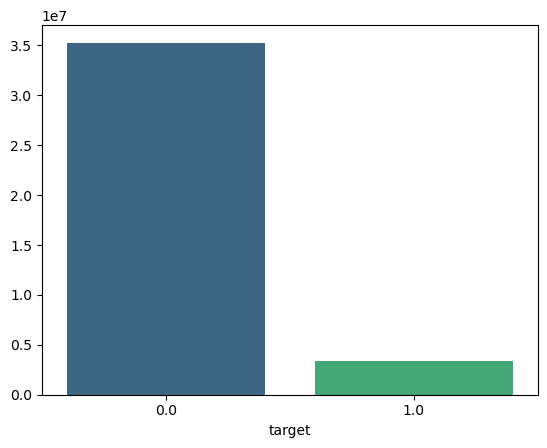

In [8]:
class_counts = df["target"].value_counts()
sns.barplot(x=class_counts.index, y=class_counts.values, palette="viridis")

# 10:1 ratio of negative class to the positive class


In [9]:
df_nona = df.dropna()

In [31]:
df_nona["target"].value_counts()

target
0.0    35050348
1.0     3401090
Name: count, dtype: int64

In [11]:
from ydata_profiling import ProfileReport
prof = ProfileReport(df_nona)
prof.to_file(output_file = 'output.html')

c:\Users\moham\anaconda3\Lib\site-packages\ydata_profiling\utils\dataframe.py:137: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df.rename(columns={"index": "df_index"}, inplace=True)


Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

100%|██████████| 9/9 [01:15<00:00,  8.35s/it]
c:\Users\moham\anaconda3\Lib\site-packages\matplotlib\image.py:181: UserWarning: Data with more than 2**24 rows cannot be accurately displayed. Downsampling to less than 2**24 rows before displaying. To remove this warning, manually downsample your data.
  warnings.warn(msg.format(n='2**24 rows'))


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

In [ ]:
df_clean =df_nona.drop_duplicates()

In [27]:
df_clean["target"].value_counts()

target
0.0    21884240
1.0     1821628
Name: count, dtype: int64

In [32]:
df_clean.to_parquet("clean_pixel_dataframe", index=False, compression="snappy")